# Milestone 1: Data Understanding, Defect Exploration and Metrics

### Objective
The task is to detect surface anomalies in industrial images and mark, for each of four defect categories, exactly which pixels are affected (semantic segmentation). Before building any model, this notebook studies the data, the mask format and the evaluation metric, so that every later modelling decision is backed by evidence from the training set.

---

## 0. Environment and Configuration

Imports, constants and a fixed random seed are defined once so that the notebook is reproducible.

In [1]:
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DATA_DIR = Path("/kaggle/input/competitions/industrial-surface-defect-detection/public")
IMG_H, IMG_W = 128, 800
DEFECT_TYPES = ["defect_a", "defect_b", "defect_c", "defect_d"]

print(f"torch {torch.__version__} | pandas {pd.__version__} | numpy {np.__version__}")
print("GPU available:", torch.cuda.is_available())

torch 2.11.0+cpu | pandas 2.3.3 | numpy 2.1.3
GPU available: False


## 1. Dataset Overview

**Objective:** verify the structure and quality of the provided files before analysis.

In [2]:
print("Files in the competition directory:")
for p in sorted(DATA_DIR.iterdir()):
    print(" -", p.name)

Files in the competition directory:
 - sample_submission.csv
 - test
 - train
 - train.csv


In [4]:
train = pd.read_csv(DATA_DIR / "train.csv")
sample_sub = pd.read_csv(DATA_DIR / "sample_submission.csv")

n_images = train.image_id.nunique()
print(f"train.csv: {train.shape[0]:,} rows x {train.shape[1]} columns")
print(f"Unique training images: {n_images:,}")
print(f"Rows per image: {len(train) / n_images:.1f}")
print("Image sizes (width, height):", train[["width", "height"]].drop_duplicates().values.tolist())

print("\nMissing values per column:")
print(train.isna().sum())
print("Duplicate (image_id, defect_type) pairs:", train.duplicated(["image_id", "defect_type"]).sum())

n_test_images = sample_sub.image_id.nunique()
print(f"\nsample_submission.csv: {len(sample_sub):,} rows covering {n_test_images:,} test images")
train.head(8)

train.csv: 45,572 rows x 5 columns
Unique training images: 11,393
Rows per image: 4.0
Image sizes (width, height): [[800, 128]]

Missing values per column:
image_id           0
defect_type        0
mask_rle       38371
width              0
height             0
dtype: int64
Duplicate (image_id, defect_type) pairs: 0

sample_submission.csv: 12,000 rows covering 3,000 test images


,image_id,defect_type,mask_rle,width,height
0,4S22I7SA34,defect_a,7255 6 7377 12 7505 12 7633 12 7762 11 7890 11...,800,128
1,4S22I7SA34,defect_b,NaN,800,128
2,4S22I7SA34,defect_c,NaN,800,128
3,4S22I7SA34,defect_d,NaN,800,128
4,DZ899111OE,defect_a,NaN,800,128
5,DZ899111OE,defect_b,NaN,800,128
6,DZ899111OE,defect_c,NaN,800,128
7,DZ899111OE,defect_d,NaN,800,128


### Observations
- The table is in **long format**: every image has exactly one row per defect type, so `rows = images x 4`.
- All images have the same size, 800 x 128 pixels (width x height), a very wide strip with aspect ratio 6.25 : 1.
- Missing values occur only in `mask_rle`. A missing mask is not corrupt data: it encodes *no defect of this type in this image*.
- There are no duplicate (image, defect) pairs, so no cleaning is required.

---

## Q1. Global Class Distribution and Clean-Image Mass

**Objective:** quantify how sparse the defects are by (a) counting positive samples per defect class and (b) counting completely clean images, i.e. images whose four masks are all empty.

In [5]:

train["has_defect"] = train.mask_rle.notna() & (train.mask_rle.astype(str).str.strip() != "")
positives = train[train.has_defect]

class_counts = positives.defect_type.value_counts().reindex(DEFECT_TYPES)
class_table = pd.DataFrame({
    "positive_images": class_counts,
    "share_of_images_%": (100 * class_counts / n_images).round(2),
})
display(class_table)

n_defective = positives.image_id.nunique()
n_clean = n_images - n_defective
print(f"Images with at least one defect: {n_defective:,}")
print(f"Completely clean images:         {n_clean:,}  ({100 * n_clean / n_images:.1f}% of all images)")

most_frequent = class_counts.idxmax()
q1_answer = int(class_counts.max() + n_clean)
print(f"\nMost frequent class: {most_frequent} ({class_counts.max():,} positives)")
print(f"Q1 answer = {class_counts.max():,} + {n_clean:,} = {q1_answer:,}")

,positive_images,share_of_images_%
defect_type,,
defect_a,1081,9.49
defect_b,313,2.75
defect_c,4100,35.99
defect_d,1707,14.98


Images with at least one defect: 5,877
Completely clean images:         5,516  (48.4% of all images)

Most frequent class: defect_c (4,100 positives)
Q1 answer = 4,100 + 5,516 = 9,616


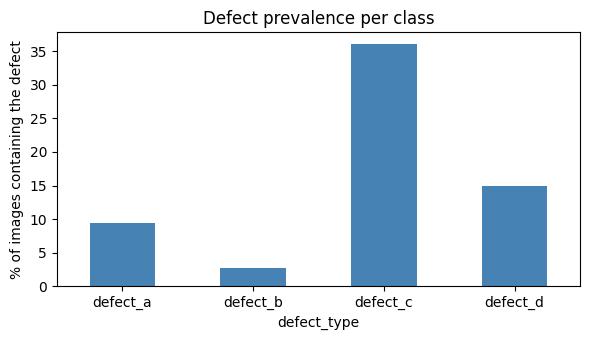

In [6]:
class_table["share_of_images_%"].plot(kind="bar", color="steelblue", figsize=(6, 3.5))
plt.ylabel("% of images containing the defect")
plt.title("Defect prevalence per class")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Interpretation
- The classes are strongly imbalanced: one class (`defect_c`) is clearly the most common, while `defect_b` is the rarest and has very few training examples. A rare class gives the model little to learn from and makes validation estimates noisy.
- A large share of all images is completely clean. Most image-class pairs are therefore empty, so a trivial "predict nothing" model would look good under plain accuracy. This motivates Dice-based metrics, a loss that does not let the background dominate, and a validation split that preserves rare classes.

---

## Q2. Multi-Label Cardinality and Co-occurrence

**Objective:** measure how many defect classes appear together on the same image.

In [8]:
cardinality = (
    positives.groupby("image_id").defect_type.nunique()
    .reindex(train.image_id.unique(), fill_value=0)
)

dist = cardinality.value_counts().sort_index().rename("images")
display(dist.to_frame())

multi_label_ids = cardinality[cardinality > 1].index
q2_answer = len(multi_label_ids)
print(f"Images with strictly more than one defect class: {q2_answer:,}")
print(f"Share of defective images that are multi-label:   {100 * q2_answer / n_defective:.1f}%")

# Which pairs of classes appear together?
presence = (
    train.pivot(index="image_id", columns="defect_type", values="has_defect")[DEFECT_TYPES].astype(int)
)
cooc = presence.T.dot(presence)
display(cooc)

,images
defect_type,
0,5516
1,4679
2,1072
3,126


Images with strictly more than one defect class: 1,198
Share of defective images that are multi-label:   20.4%


defect_type,defect_a,defect_b,defect_c,defect_d
defect_type,,,,
defect_a,1081,42,310,234
defect_b,42,313,95,64
defect_c,310,95,4100,705
defect_d,234,64,705,1707


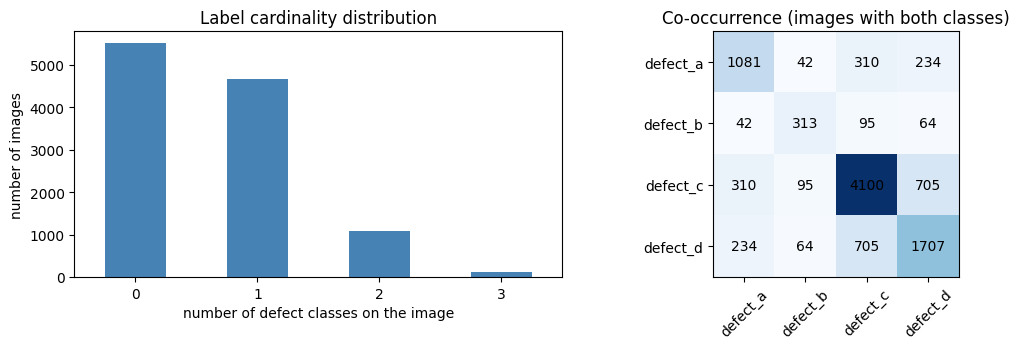

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
dist.plot(kind="bar", ax=ax[0], color="steelblue")
ax[0].set_xlabel("number of defect classes on the image")
ax[0].set_ylabel("number of images")
ax[0].set_title("Label cardinality distribution")
ax[0].tick_params(axis="x", rotation=0)

im = ax[1].imshow(cooc.values, cmap="Blues")
ax[1].set_xticks(range(4)); ax[1].set_xticklabels(DEFECT_TYPES, rotation=45)
ax[1].set_yticks(range(4)); ax[1].set_yticklabels(DEFECT_TYPES)
for i in range(4):
    for j in range(4):
        ax[1].text(j, i, int(cooc.values[i, j]), ha="center", va="center")
ax[1].set_title("Co-occurrence (images with both classes)")
plt.tight_layout()
plt.show()

### Interpretation
- The cardinality distribution peaks at 0 and 1; multi-label images are a minority of the defective images but are far from negligible, and no image carries all four defect types.
- Co-occurrence is not uniform: some class pairs appear together much more often than others, while `defect_b` rarely appears with anything.

---

## Q3. Spatial Mutual Exclusivity of Defect Masks

**Objective:** test whether any pixel is labelled with two or more defect classes at once, and use the result to justify the output-head design of the segmentation model.

In [10]:
def rle_decode(rle, shape=(IMG_H, IMG_W)):
    """Decode a 1-based, column-major RLE string into a binary (H, W) mask."""
    flat = np.zeros(shape[0] * shape[1], dtype=np.uint8)
    if isinstance(rle, str) and rle.strip():
        tokens = [int(t) for t in rle.split()]
        starts = np.array(tokens[0::2]) - 1        
        ends = starts + np.array(tokens[1::2])      
        for s, e in zip(starts, ends):
            flat[max(s, 0):min(e, flat.size)] = 1 
    return flat.reshape(shape, order="F")


toy = rle_decode("3 4 10 2", shape=(4, 4))
print(toy)
print("foreground pixels:", toy.sum())

[[0 1 0 0]
 [0 1 1 0]
 [1 0 1 0]
 [1 0 0 0]]
foreground pixels: 6


In [11]:
multi_rows = positives[positives.image_id.isin(multi_label_ids)]

pair_overlap = np.zeros((4, 4), dtype=np.int64)   # sum over images of |M_i AND M_j|
pixels_with_2plus_labels = 0

for image_id, rows in multi_rows.groupby("image_id"):
    stack = np.zeros((4, IMG_H, IMG_W), dtype=np.uint8)
    for _, r in rows.iterrows():
        stack[DEFECT_TYPES.index(r.defect_type)] = rle_decode(r.mask_rle)

    for i in range(4):
        for j in range(4):
            pair_overlap[i, j] += int(np.logical_and(stack[i], stack[j]).sum())
    pixels_with_2plus_labels += int((stack.sum(axis=0) >= 2).sum())

overlap_df = pd.DataFrame(pair_overlap, index=DEFECT_TYPES, columns=DEFECT_TYPES)
print(f"Multi-label images audited: {multi_rows.image_id.nunique():,}")
print("\nPairwise overlap matrix (diagonal = total area of each class):")
display(overlap_df)

off_diagonal = int(np.triu(pair_overlap, k=1).sum())
print(f"Sum of off-diagonal pair overlaps (class i vs class j, i < j): {off_diagonal:,}")
print(f"Q3 answer: pixels carrying >= 2 defect labels = {pixels_with_2plus_labels:,}")

verdict = ("defect masks are spatially disjoint -> a background + 4-class softmax partition is consistent with the labels"
           if pixels_with_2plus_labels == 0 else
           "defect masks overlap -> a softmax head cannot represent the labels; use 4 independent sigmoids")
print("Verdict:", verdict)

Multi-label images audited: 1,198

Pairwise overlap matrix (diagonal = total area of each class):


,defect_a,defect_b,defect_c,defect_d
defect_a,271621,0,0,0
defect_b,0,103350,0,0
defect_c,0,0,3711253,0
defect_d,0,0,0,5986554


Sum of off-diagonal pair overlaps (class i vs class j, i < j): 0
Q3 answer: pixels carrying >= 2 defect labels = 0
Verdict: defect masks are spatially disjoint -> a background + 4-class softmax partition is consistent with the labels


### Interpretation
- The diagonal of the matrix holds each class's total area (a mask intersected with itself), so it is never zero for a class that has masks. Only the **off-diagonal** entries measure overlap between different classes.
- The audit total printed above is the number of pixels labelled by two or more classes. It differs from the sum of pairwise overlaps only when a pixel carries three labels (the pair sum would count it three times, the pixel count once).
- **Decision rule:** a total of zero means the ground truth is a strict spatial partition, so mutually exclusive classes (softmax with a background channel, K = 5) match the label structure; any positive total means the labels are genuinely multi-label at pixel level and independent sigmoid channels (K = 4) with a BCE-style loss are required.

---